# 01 — Analyse exploratoire des données Home Credit

**Projet 6 OpenClassrooms — Modèle de scoring crédit « Prêt à dépenser »**

**Objectif du notebook** : comprendre les données brutes avant de les transformer. Ce notebook répond aux prérequis de l'étape 1 :
- explorer les données brutes, vérifier formats, doublons et valeurs manquantes ;
- identifier les clés de jointure entre les tables ;
- prendre en compte les enjeux métier, en particulier le **déséquilibre des classes**.

**Sources méthodologiques**
- Kernel Kaggle [Start Here: A Gentle Introduction](https://www.kaggle.com/code/willkoehrsen/start-here-a-gentle-introduction/notebook) (Will Koehrsen) pour l'EDA ;
- cours *Maîtriser l'apprentissage supervisé* 

### Rappel : structure relationnelle des données

```
                        application_{train|test}   (1 ligne = 1 demande de crédit = 1 client, clé SK_ID_CURR)
                         /                       \
         bureau  (SK_ID_CURR)                 previous_application (SK_ID_CURR, SK_ID_PREV)
   crédits dans d'autres institutions          demandes passées chez Home Credit
             |                                   /            |                 \
   bureau_balance (SK_ID_BUREAU)       POS_CASH_balance   installments_payments   credit_card_balance
   historique mensuel                  (SK_ID_PREV, SK_ID_CURR) : historiques mensuels / échéances
```

Les tables secondaires ont **plusieurs lignes par client**. Il faudra les **agréger** (une ligne par client) avant de les joindre à la table principale : c'est l'objet du notebook 02.

In [2]:

pip install missingno

Note: you may need to restart the kernel to use updated packages.


In [1]:
# -------------------------- Imports --------------------------
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns

sns.set()
pd.set_option("display.max_columns", 50)

from src.settings import (
    APPLICATION_TRAIN_FILE,
    APPLICATION_TEST_FILE,
    BUREAU_FILE,
    BUREAU_BALANCE_FILE,
    PREVIOUS_APPLICATION_FILE,
    POS_CASH_FILE,
    INSTALLMENTS_FILE,
    CREDIT_CARD_FILE,
    COLUMNS_DESCRIPTION_FILE,
    FIGURES_PATH,
    ID_COLUMN,
    TARGET,
)
from src.data_processing_functions import (
    load_csv,
    load_columns_description,
    missing_values_table,
)

FIGURES_PATH.mkdir(parents=True, exist_ok=True)

## 1. Table principale `application_train`

Chaque ligne est une demande de crédit. `TARGET = 1` signifie que le client a eu des **difficultés de paiement** (retard de plus de X jours sur au moins une des premières échéances) ; `TARGET = 0` qu'il a remboursé normalement.

> `load_csv` réduit la précision numérique (float64 → float32) : sur une machine à 8 Go de RAM, c'est ce qui permet de traiter les 2,5 Go de CSV sans saturer la mémoire.

In [2]:
app_train = load_csv(APPLICATION_TRAIN_FILE)
app_test = load_csv(APPLICATION_TEST_FILE)
app_train.head()

application_train.csv : 307,511 lignes x 122 colonnes
application_test.csv : 48,744 lignes x 121 colonnes


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
print("Types de colonnes :")
print(app_train.dtypes.astype(str).value_counts())

categorical_cols = app_train.select_dtypes(include=["object", "string"]).columns.tolist()
print(f"\n{len(categorical_cols)} colonnes catégorielles :")
app_train[categorical_cols].nunique().sort_values()

Types de colonnes :
float32    65
int8       37
str        16
int32       2
int16       2
Name: count, dtype: int64

16 colonnes catégorielles :


NAME_CONTRACT_TYPE             2
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
EMERGENCYSTATE_MODE            2
CODE_GENDER                    3
HOUSETYPE_MODE                 3
FONDKAPREMONT_MODE             4
NAME_EDUCATION_TYPE            5
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
NAME_TYPE_SUITE                7
WEEKDAY_APPR_PROCESS_START     7
WALLSMATERIAL_MODE             7
NAME_INCOME_TYPE               8
OCCUPATION_TYPE               18
ORGANIZATION_TYPE             58
dtype: int64

Le fichier `HomeCredit_columns_description.csv` documente chaque variable. Une petite fonction permet de le consulter rapidement (utile pour l'analyse métier des features).

Ce code sert à consulter automatiquement le dictionnaire des variables de ton dataset financier, afin de comprendre la signification de certaines colonnes avant de les analyse

In [4]:
columns_description = load_columns_description(COLUMNS_DESCRIPTION_FILE)


def describe_column(name: str) -> pd.DataFrame:
    return columns_description.loc[
        columns_description["Row"] == name, ["Table", "Row", "Description", "Special"]
    ]


pd.concat([describe_column(c) for c in ["TARGET", "EXT_SOURCE_1", "DAYS_EMPLOYED", "AMT_ANNUITY"]])

,Table,Row,Description,Special
2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
44,application_{train|test}.csv,EXT_SOURCE_1,Normalized score from external data source,normalized
21,application_{train|test}.csv,DAYS_EMPLOYED,How many days before the application the perso...,time only relative to the application
12,application_{train|test}.csv,AMT_ANNUITY,Loan annuity,NaN
141,bureau.csv,AMT_ANNUITY,Annuity of the Credit Bureau credit,NaN
179,previous_application.csv,AMT_ANNUITY,Annuity of previous application,NaN


## 2. Variable cible : un fort déséquilibre de classes

TARGET
0    282686
1     24825
Name: count, dtype: int64

Taux de défaut : 8.07%


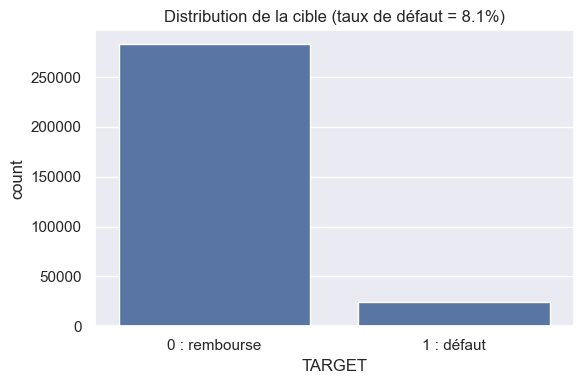

In [14]:
target_counts = app_train[TARGET].value_counts()
target_rate = app_train[TARGET].mean()
print(target_counts)
print(f"\nTaux de défaut : {target_rate:.2%}")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=TARGET, data=app_train, ax=ax)
ax.set_title(f"Distribution de la cible (taux de défaut = {target_rate:.1%})")
ax.set_xticks([0, 1], ["0 : rembourse", "1 : défaut"])
plt.tight_layout()
plt.savefig(FIGURES_PATH / "01_target_distribution.png", dpi=100)
plt.show()

**Lecture et conséquences méthodologiques**

Environ **8 % des clients font défaut**, soit environ 1 client sur 12.

- **Métriques adaptées** : AUC-ROC, rappel (recall) sur la classe 1, F1, et surtout le **coût métier** (FN = 10 × FP) avec un seuil de décision optimisé.
- **Validation** : `StratifiedKFold` et `train_test_split(..., stratify=y)` pour conserver ces 8 % dans chaque échantillon.
- **Apprentissage** : pondération des classes (`class_weight="balanced"`, `scale_pos_weight`) ou rééchantillonnage (SMOTE), **uniquement sur les plis d'entraînement**.

## 3. Doublons et clé de jointure

In [4]:
print(f"SK_ID_CURR unique dans train : {app_train[ID_COLUMN].is_unique}")
print(f"SK_ID_CURR unique dans test  : {app_test[ID_COLUMN].is_unique}")
print(f"Lignes entièrement dupliquées (train) : {app_train.duplicated().sum()}")
print(f"Lignes dupliquées hors identifiant     : {app_train.drop(columns=ID_COLUMN).duplicated().sum()}")
print(f"Clients présents à la fois en train et test : "
      f"{len(set(app_train[ID_COLUMN]) & set(app_test[ID_COLUMN]))}")

SK_ID_CURR unique dans train : True
SK_ID_CURR unique dans test  : True
Lignes entièrement dupliquées (train) : 0
Lignes dupliquées hors identifiant     : 0
Clients présents à la fois en train et test : 0


## 4. Valeurs manquantes

In [5]:
missing_train = missing_values_table(app_train)
print(f"{len(missing_train)} colonnes sur {app_train.shape[1]} ont des valeurs manquantes")
print(f"dont {(missing_train['pct_manquants'] > 50).sum()} avec plus de 50 % de manquants")
missing_train.head(20)

67 colonnes sur 122 ont des valeurs manquantes
dont 41 avec plus de 50 % de manquants


,nb_manquants,pct_manquants,dtype
COMMONAREA_MEDI,214865,69.872297,float32
COMMONAREA_AVG,214865,69.872297,float32
COMMONAREA_MODE,214865,69.872297,float32
NONLIVINGAPARTMENTS_MEDI,213514,69.432963,float32
NONLIVINGAPARTMENTS_MODE,213514,69.432963,float32
NONLIVINGAPARTMENTS_AVG,213514,69.432963,float32
FONDKAPREMONT_MODE,210295,68.386172,str
LIVINGAPARTMENTS_MODE,210199,68.354953,float32
LIVINGAPARTMENTS_MEDI,210199,68.354953,float32
LIVINGAPARTMENTS_AVG,210199,68.354953,float32


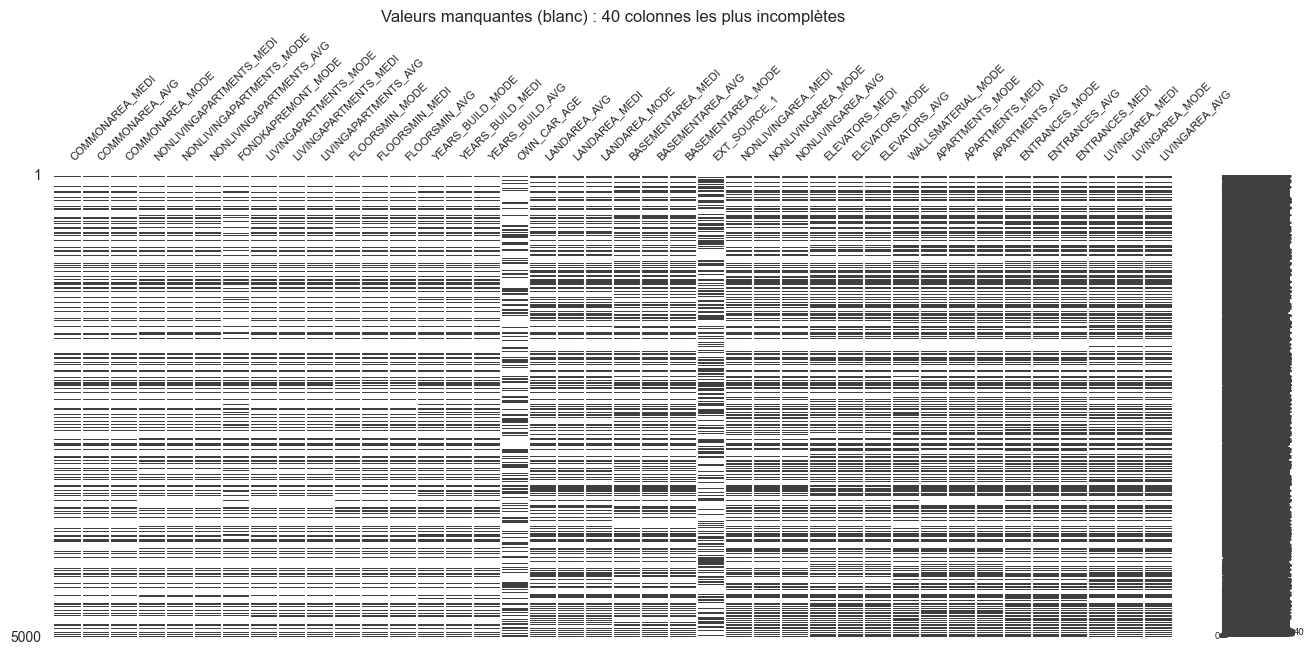

In [6]:
# Visualisation missingno sur les 40 colonnes les plus incomplètes (échantillon de 5 000 lignes)
cols_most_missing = missing_train.head(40).index.tolist()
msno.matrix(app_train[cols_most_missing].sample(5000, random_state=42), figsize=(16, 6), fontsize=8)
plt.title("Valeurs manquantes (blanc) : 40 colonnes les plus incomplètes")
plt.savefig(FIGURES_PATH / "01_missingno_matrix.png", dpi=100, bbox_inches="tight")
plt.show()

In [7]:
# Le fait qu'une valeur manque est-il lié au risque ? (valeurs manquantes "informatives")
rows = []
for col in ["EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE", "OCCUPATION_TYPE", "COMMONAREA_AVG"]:
    is_missing = app_train[col].isna()
    rows.append({
        "variable": col,
        "pct_manquants": round(100 * is_missing.mean(), 1),
        "taux_defaut_si_manquant": round(100 * app_train.loc[is_missing, TARGET].mean(), 2),
        "taux_defaut_si_renseigne": round(100 * app_train.loc[~is_missing, TARGET].mean(), 2),
    })
pd.DataFrame(rows)

,variable,pct_manquants,taux_defaut_si_manquant,taux_defaut_si_renseigne
0,EXT_SOURCE_1,56.4,8.52,7.50
1,EXT_SOURCE_3,19.8,9.31,7.77
2,OWN_CAR_AGE,66.0,8.50,7.24
3,OCCUPATION_TYPE,31.3,6.51,8.79
4,COMMONAREA_AVG,69.9,8.57,6.91


**Lecture**
- Les **données du logement** (suffixes `_AVG`, `_MODE`, `_MEDI`) manquent pour 50 à 70 % des clients ; elles se déplacent en bloc (même motif sur la matrice missingno) : soit le client a renseigné son logement, soit non.
- Le **taux de défaut diffère selon que la valeur est manquante ou non** : l'absence d'information est elle-même un signal (valeurs *Missing Not At Random*).
- Dans le dataset Home Credit Default Risk de Kaggle, EXT_SOURCE_1, EXT_SOURCE_2 et EXT_SOURCE_3 sont trois scores de risque issus de sources de données externes, intégrés au dossier de chaque demandeur de crédit.
- si des données sont manquantes, ce sont déjà des informations importantes dans un score de crédit.

**Décision documentée** : 
1. LightGBM et XGBoost gèrent nativement les `NaN` (ils apprennent la meilleure direction pour les valeurs manquantes à chaque split).
2. Pour les modèles qui ne les gèrent pas (régression logistique, MLP, Random Forest scikit-learn), l'imputation sera faite **dans un `Pipeline` scikit-learn**, donc recalculée sur chaque pli d'entraînement de la validation croisée. Imputer maintenant sur tout le jeu ferait **fuiter de l'information** du jeu de validation vers l'entraînement.

## 5. Anomalies : âge et ancienneté dans l'emploi

Les variables `DAYS_*` sont exprimées en jours **négatifs** par rapport à la date de la demande.

In [8]:
print("Âge (années) :")
print((app_train["DAYS_BIRTH"] / -365).describe().round(1))
print("\nAncienneté emploi (années) :")
print((app_train["DAYS_EMPLOYED"] / -365).describe().round(1))

Âge (années) :
count    307511.0
mean         43.9
std          12.0
min          20.5
25%          34.0
50%          43.2
75%          53.9
max          69.1
Name: DAYS_BIRTH, dtype: float64

Ancienneté emploi (années) :
count    307511.0
mean       -174.8
std         387.1
min       -1000.7
25%           0.8
50%           3.3
75%           7.6
max          49.1
Name: DAYS_EMPLOYED, dtype: float64


In [9]:
anomaly = app_train["DAYS_EMPLOYED"] == 365243
print(f"DAYS_EMPLOYED = 365243 (≈ 1000 ans !) : {anomaly.sum():,} clients ({anomaly.mean():.1%})")
print(f"Taux de défaut des anomalies     : {app_train.loc[anomaly, TARGET].mean():.2%}")
print(f"Taux de défaut des non-anomalies : {app_train.loc[~anomaly, TARGET].mean():.2%}")
print("\nType de revenu des anomalies :")
print(app_train.loc[anomaly, "NAME_INCOME_TYPE"].value_counts())

DAYS_EMPLOYED = 365243 (≈ 1000 ans !) : 55,374 clients (18.0%)
Taux de défaut des anomalies     : 5.40%
Taux de défaut des non-anomalies : 8.66%

Type de revenu des anomalies :
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64


**Lecture** : la valeur 365243 n'est pas une erreur de saisie aléatoire, c'est un **code** utilisé pour les **retraités** (et quelques chômeurs) qui n'ont pas d'employeur. Ces clients font **moins défaut** (environ 5,4 % contre 8,7 %).On regarde qui sont ces clients : 55 352 sont retraités et 22 sont chômeurs. Ce n'est donc pas une faute de frappe au hasard. Home Credit a mis un « code bouche-trou » pour les gens sans employeur : comme la case « depuis quand travaillez-vous ici ? » n'avait pas de sens pour eux, le système a rempli une valeur arbitraire.

**Décision** (reprise du kernel *Gentle Introduction*) : on crée un indicateur `DAYS_EMPLOYED_ANOM` pour ne pas perdre cette information, puis on remplace 365243 par `NaN` pour ne pas fausser la distribution. La même valeur sentinelle apparaît dans les colonnes `DAYS_*` de `previous_application` et sera traitée de la même façon.

## 6. Corrélations avec la cible

On regarde la matrice de corrélation, ici limitée aux corrélations avec `TARGET` (122 colonnes).

In [10]:
numeric_train = app_train.select_dtypes(include=[np.number])
correlations_target = numeric_train.corr()[TARGET].drop(TARGET).sort_values()
print("Corrélations les plus négatives (protectrices) :")
print(correlations_target.head(8).round(3))
print("\nCorrélations les plus positives (facteurs de risque) :")
print(correlations_target.tail(8).round(3))

Corrélations les plus négatives (protectrices) :
EXT_SOURCE_3      -0.179
EXT_SOURCE_2      -0.160
EXT_SOURCE_1      -0.155
DAYS_EMPLOYED     -0.045
FLOORSMAX_AVG     -0.044
FLOORSMAX_MEDI    -0.044
FLOORSMAX_MODE    -0.043
AMT_GOODS_PRICE   -0.040
Name: TARGET, dtype: float64

Corrélations les plus positives (facteurs de risque) :
REG_CITY_NOT_LIVE_CITY         0.044
FLAG_EMP_PHONE                 0.046
REG_CITY_NOT_WORK_CITY         0.051
DAYS_ID_PUBLISH                0.051
DAYS_LAST_PHONE_CHANGE         0.055
REGION_RATING_CLIENT           0.059
REGION_RATING_CLIENT_W_CITY    0.061
DAYS_BIRTH                     0.078
Name: TARGET, dtype: float64


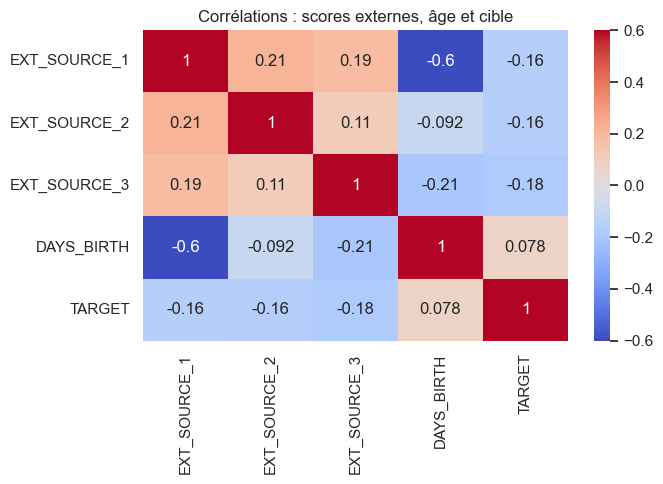

In [11]:
ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "DAYS_BIRTH", TARGET]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(app_train[ext_cols].corr(), annot=True, cmap="coolwarm", vmin=-0.6, vmax=0.6, ax=ax)
ax.set_title("Corrélations : scores externes, âge et cible")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "01_corr_ext_sources.png", dpi=100)
plt.show()

Aucune corrélation ne dépasse plus de 0,2 dans un sens comme dans l'autre

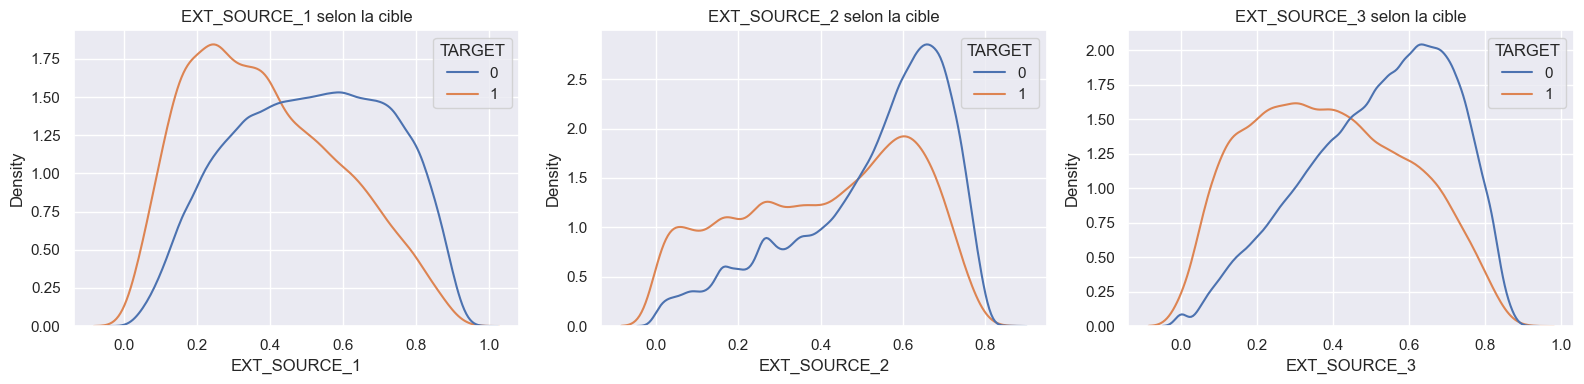

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    sns.kdeplot(data=app_train, x=col, hue=TARGET, common_norm=False, ax=ax)
    ax.set_title(f"{col} selon la cible")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "01_kde_ext_sources.png", dpi=100)
plt.show()

**Lecture**
- - Bleu — TARGET = 0 : clients n'ayant pas rencontré les difficultés de remboursement définies par la cible.
- Orange — TARGET = 1 : clients ayant rencontré ces difficultés.
- L'axe horizontal représente la valeur normalisée du score externe
- L'axe vertical représente une densité de probabilité, et non un nombre de clients ou un taux de défaut.

- 
- Les trois **scores externes `EXT_SOURCE_*`** (scores de crédit normalisés fournis par des organismes tiers) sont les variables les plus discriminantes : plus le score est élevé, moins le risque est élevé. Les distributions des bons et mauvais clients sont nettement décalées.
- Les corrélations restent **faibles en valeur absolue** (< 0,2) : aucune variable seule ne suffit. C'est la combinaison non linéaire de nombreuses variables qui fera la performance, ce qui justifie des modèles de type boosting.
- `DAYS_BIRTH` est positivement corrélé à la cible : comme les jours sont négatifs, cela signifie que **les clients plus jeunes font davantage défaut**.

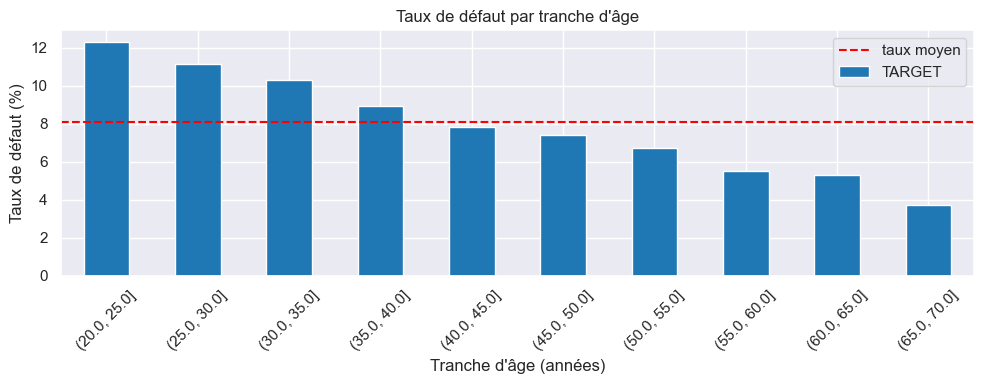

In [15]:
age_years = app_train["DAYS_BIRTH"] / -365
age_bins = pd.cut(age_years, bins=np.linspace(20, 70, 11))
default_by_age = app_train.groupby(age_bins, observed=True)[TARGET].mean() * 100

fig, ax = plt.subplots(figsize=(10, 4))
default_by_age.plot(kind="bar", ax=ax, color="tab:blue")
ax.axhline(100 * target_rate, color="red", linestyle="--", label="taux moyen")
ax.set_ylabel("Taux de défaut (%)")
ax.set_xlabel("Tranche d'âge (années)")
ax.set_title("Taux de défaut par tranche d'âge")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "01_default_by_age.png", dpi=100)
plt.show()

- Effectivement les jeubes ont plus tendance à faire défaut

## 7. Variables catégorielles et taux de défaut

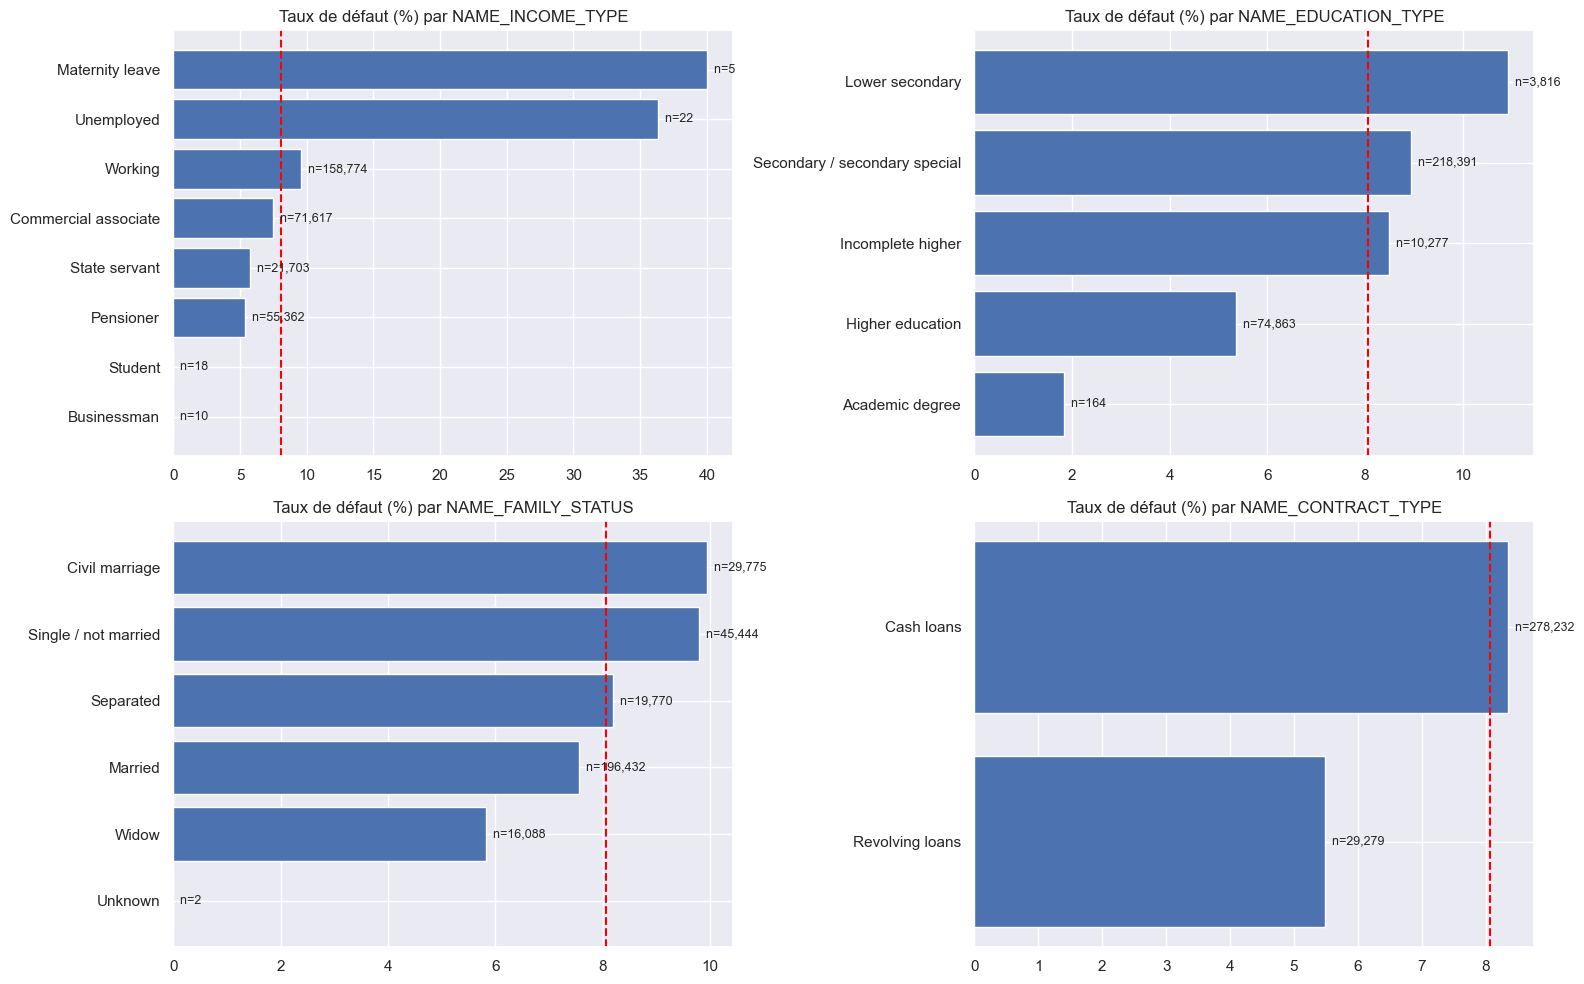

CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col in zip(
    axes.ravel(),
    ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_CONTRACT_TYPE"],
):
    stats = app_train.groupby(col)[TARGET].agg(["mean", "size"]).sort_values("mean")
    ax.barh(stats.index.astype(str), 100 * stats["mean"])
    for i, (rate, n) in enumerate(zip(stats["mean"], stats["size"])):
        ax.text(100 * rate, i, f"  n={n:,}", va="center", fontsize=9)
    ax.axvline(100 * target_rate, color="red", linestyle="--")
    ax.set_title(f"Taux de défaut (%) par {col}")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "01_default_by_category.png", dpi=100)
plt.show()

print(app_train["CODE_GENDER"].value_counts())

**Lecture**
- Le risque varie fortement selon le **type de revenu** (chômeurs, congé maternité : très risqués mais rares ; retraités, fonctionnaires : moins risqués) et le **niveau d'éducation**, qui est une variable **ordinale** (secondaire < supérieur incomplet < supérieur). 

- `CODE_GENDER` contient **4 valeurs `XNA`** : elles seront supprimées (choix du kernel jsaguiar).


## 8. Angle économique : poids de l'endettement

Le kernel crée des ratios financiers classiques en analyse crédit. On vérifie leur pouvoir discriminant avant de les construire : 
- taux d'effort (annuité / revenu)
- et `PAYMENT_RATE` (annuité / montant du crédit, qui est l'inverse de la durée du prêt).

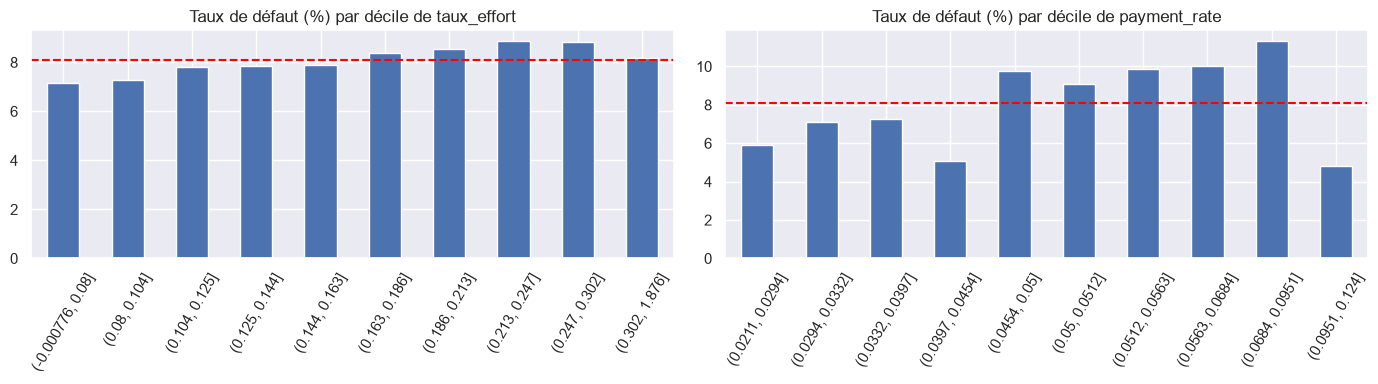

In [17]:
ratios = pd.DataFrame({
    "taux_effort": app_train["AMT_ANNUITY"] / app_train["AMT_INCOME_TOTAL"],
    "payment_rate": app_train["AMT_ANNUITY"] / app_train["AMT_CREDIT"],
    TARGET: app_train[TARGET],
})
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["taux_effort", "payment_rate"]):
    deciles = pd.qcut(ratios[col], 10, duplicates="drop")
    (ratios.groupby(deciles, observed=True)[TARGET].mean() * 100).plot(kind="bar", ax=ax)
    ax.axhline(100 * target_rate, color="red", linestyle="--")
    ax.set_title(f"Taux de défaut (%) par décile de {col}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "01_default_by_ratio_deciles.png", dpi=100)
plt.show()

**Lecture**
- **Taux d'effort** : le risque augmente avec la part du revenu consacrée au remboursement (d'environ 7 % à 9 % de défaut), de façon quasi monotone mais modeste. C'est l'intuition économique attendue.
- **`PAYMENT_RATE`** : la relation est **non monotone**. Le risque croît avec le `PAYMENT_RATE` (prêts plus courts) jusqu'au 9e décile (environ 11 %), puis **chute brutalement au dernier décile** (environ 5 %, prêts très courts) ; on observe aussi un creux au 4e décile. Ces paliers reflètent probablement des durées de prêt standardisées (produits commerciaux types).
- Une régression logistique, qui suppose une relation linéaire avec le logit, capterait mal ces formes, alors que les arbres de décision les découpent naturellement. C'est un argument de plus pour les modèles de boosting.

## 9. Tables secondaires : volumétrie, doublons, couverture

Pour chaque table, on vérifie la volumétrie, les doublons, le taux de valeurs manquantes, le nombre moyen de lignes par client et la **couverture** (part des clients de `application_train` présents dans la table). Les tables sont chargées **une par une** et libérées aussitôt pour préserver la RAM.

In [18]:
import gc

secondary_tables = {
    "bureau": (BUREAU_FILE, "SK_ID_CURR"),
    "bureau_balance": (BUREAU_BALANCE_FILE, "SK_ID_BUREAU"),
    "previous_application": (PREVIOUS_APPLICATION_FILE, "SK_ID_CURR"),
    "POS_CASH_balance": (POS_CASH_FILE, "SK_ID_CURR"),
    "installments_payments": (INSTALLMENTS_FILE, "SK_ID_CURR"),
    "credit_card_balance": (CREDIT_CARD_FILE, "SK_ID_CURR"),
}
train_ids = set(app_train[ID_COLUMN])
bureau_ids = None
summary = []
for name, (path, key) in secondary_tables.items():
    df = load_csv(path)
    if name == "bureau":
        bureau_ids = set(df["SK_ID_BUREAU"])
    if key == "SK_ID_CURR":
        coverage = len(train_ids & set(df[key])) / len(train_ids)
    else:  # bureau_balance se rattache à bureau, pas directement au client
        coverage = np.nan
    summary.append({
        "table": name,
        "cle_jointure": key,
        "nb_lignes": df.shape[0],
        "nb_colonnes": df.shape[1],
        "nb_doublons": int(df.duplicated().sum()),
        "pct_cellules_manquantes": round(100 * df.isna().mean().mean(), 1),
        "lignes_par_cle": round(df.groupby(key).size().mean(), 1),
        "couverture_clients_train": coverage,
    })
    if name == "bureau_balance":
        print(f"bureau_balance : {len(set(df['SK_ID_BUREAU']) & bureau_ids) / len(bureau_ids):.1%} "
              "des crédits de bureau ont un historique mensuel")
    del df
    gc.collect()

summary = pd.DataFrame(summary).set_index("table")
summary

bureau.csv : 1,716,428 lignes x 17 colonnes


bureau_balance.csv : 27,299,925 lignes x 3 colonnes


bureau_balance : 45.1% des crédits de bureau ont un historique mensuel


previous_application.csv : 1,670,214 lignes x 37 colonnes


POS_CASH_balance.csv : 10,001,358 lignes x 8 colonnes


installments_payments.csv : 13,605,401 lignes x 8 colonnes


credit_card_balance.csv : 3,840,312 lignes x 23 colonnes


,cle_jointure,nb_lignes,nb_colonnes,nb_doublons,pct_cellules_manquantes,lignes_par_cle,couverture_clients_train
table,,,,,,,
bureau,SK_ID_CURR,1716428,17,0,13.5,5.6,0.856851
bureau_balance,SK_ID_BUREAU,27299925,3,0,0.0,33.4,NaN
previous_application,SK_ID_CURR,1670214,37,0,18.0,4.9,0.946493
POS_CASH_balance,SK_ID_CURR,10001358,8,0,0.1,29.7,0.941248
installments_payments,SK_ID_CURR,13605401,8,0,0.0,40.1,0.948399
credit_card_balance,SK_ID_CURR,3840312,23,0,6.7,37.1,0.282608


**Lecture**
- **Aucun doublon** de lignes dans les tables secondaires : les fusions ne créeront pas de lignes parasites, à condition d'**agréger d'abord** (plusieurs lignes par client → une ligne).
- La **couverture est incomplète** : environ 14 % des clients n'ont aucun historique au bureau de crédit, environ 5 % aucune demande précédente chez Home Credit, et **seuls 28 % ont une carte de crédit** suivie. Cela correspond à la cible métier de « Prêt à dépenser » (*clients avec peu ou pas d'historique de prêt*). On utilisera donc des **jointures à gauche** (`how="left"`) : un client sans historique est conservé, avec des `NaN` dans les features agrégées.
- `bureau_balance` ne se joint pas directement au client : il faut passer par `bureau` via `SK_ID_BUREAU` (agrégation en deux niveaux).

## 10. Synthèse et décisions pour la préparation (notebook 02)

| Constat | Décision |
|---|---|
| 8 % de défauts (déséquilibre) | Stratification, pondération des classes, métriques AUC, rappel et coût métier |
| Tables relationnelles, plusieurs lignes par client | Agrégations par client (kernel jsaguiar), puis jointures à gauche sur `SK_ID_CURR` |
| Valeurs manquantes nombreuses et informatives | Conservées ; imputation éventuelle dans un `Pipeline` pendant la validation croisée |
| `DAYS_EMPLOYED = 365243` (retraités) | Indicateur `DAYS_EMPLOYED_ANOM`, puis `NaN` |
| 4 lignes `CODE_GENDER = XNA` | Supprimées |
| `EXT_SOURCE_*` et âge très discriminants, relations non linéaires | Ratios financiers et modèles de boosting |
| Aucun doublon, `SK_ID_CURR` unique | Contrôle du nombre de lignes après chaque jointure |